# Figure S23 — Mineral compositions during fractional crystallization

## 1. Imports and shared Science Advances setup

This section follows `00_Setup/Plotting_Setup.ipynb`. There are no custom functions. The MELTS v1.2.0 and Green2025 calculations remain explicit below.

In [1]:
from pathlib import Path
import hashlib
import os
from tempfile import TemporaryDirectory

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from PIL import Image

import petthermotools as ptt
import Thermobar as pt

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')

mpl.rcParams.update({
    'font.family':'sans-serif','font.sans-serif':[PUBLICATION_FONT],
    'font.size':BASE_TEXT_SIZE_PT,'axes.labelsize':BASE_TEXT_SIZE_PT,
    'axes.titlesize':BASE_TEXT_SIZE_PT,'xtick.labelsize':BASE_TEXT_SIZE_PT,
    'ytick.labelsize':BASE_TEXT_SIZE_PT,'legend.fontsize':BASE_TEXT_SIZE_PT,
    'legend.title_fontsize':BASE_TEXT_SIZE_PT,'figure.facecolor':'white',
    'axes.facecolor':'white','axes.grid':False,'axes.spines.top':True,
    'axes.spines.right':True,'axes.linewidth':0.5,'lines.linewidth':0.75,
    'xtick.direction':'in','ytick.direction':'in','xtick.major.width':0.5,
    'ytick.major.width':0.5,'xtick.minor.visible':False,
    'ytick.minor.visible':False,'savefig.dpi':EXPORT_DPI,
    'savefig.facecolor':'white','savefig.transparent':False,
    'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none',
})
print('Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.')

alphaMELTS for Python files successfully located.
If using the Green et al. (2025) or Weller et al. (2024) thermodynamic models please run `ptt.activate_petthermotools_env()` prior to any calculations.


nGibbs not installed — nGibbs emulators are unavailable. Install it if you'd like with `ptt.install_nGibbs()` (~300 MB storage required).


Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.


## 2. Figure S23 paths, data, and model choices

In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'SA_MI_Draft_FinalFigures_Work/DataSheets').is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from inside the Glacier Peak Efforts project.')

WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
CURRENT_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_S23_Fractional_Crystallization'
OUTPUT_DIRECTORY = CURRENT_DIRECTORY / 'Figure_S23_Fractional_Crystallization_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
S1_PATH = WORK_ROOT / 'DataSheets' / 'Updated_Oct20' / 'Dechert_S1_AllData.xlsx'
if not S1_PATH.is_file():
    raise FileNotFoundError(f'Missing S1 workbook: {S1_PATH}')
SOURCE_HASH_BEFORE = hashlib.sha256(S1_PATH.read_bytes()).hexdigest()

SAMPLE_ORDER = ['74D','74A','75','76A']
SAMPLE_COLORS = {'74A':'#D55E00','74D':'#F4A261','75':'#56B4E9','76A':'#0072B2'}
SAMPLE_LABELS = {'74A':'B Base','74D':'B Middle','75':'G Top','76A':'G Middle'}
PHASE_MARKERS = {'plag':'o','pxy':'s'}
PHASE_LABELS = {'plag':'Plagioclase-hosted MI','pxy':'Pyroxene-hosted MI'}
WR_OXIDES = ['SiO2','TiO2','Al2O3','FeOt','MnO','MgO','CaO','Na2O','K2O','P2O5']
GLASS_COLUMNS = ['base_name','mineral_phase','SiO2_SEMGlass_AnhydoNorm','TiO2_SEMGlass_AnhydoNorm','Al2O3_SEMGlass_AnhydoNorm','FeOtt_SEMGlass_AnhydoNorm','MnO_SEMGlass_AnhydoNorm','MgO_SEMGlass_AnhydoNorm','CaO_SEMGlass_AnhydoNorm','Na2O_SEMGlass_AnhydoNorm','K2O_SEMGlass_AnhydoNorm','P2O5_SEMGlass_AnhydoNorm','H2O_Liq_SatP','CO2_Liq_SatP','P_bar_SatP','T_Liq_C_SatP','An#_host','Mg#_host','Predict_Mineral_host']
print(f'Source: {S1_PATH}')
print(f'Output directory: {OUTPUT_DIRECTORY}')

Source: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20/Dechert_S1_AllData.xlsx
Output directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S23_Fractional_Crystallization/Figure_S23_Fractional_Crystallization_Final


## 3. Read and prepare whole-rock, melt-inclusion, and host-mineral data

In [3]:
source = pd.read_excel(S1_PATH, sheet_name='MI_Hosts_Plag_Pxy')
whole_rock_source = pd.read_excel(S1_PATH, sheet_name='Whole_Rock')

whole_rock = whole_rock_source.set_index('Sample')[[f'{oxide}_XRF_Anhydrous_wt_pct' for oxide in WR_OXIDES]].T
whole_rock.index = WR_OXIDES
whole_rock.index.name = 'oxide'
whole_rock.columns.name = 'sample'

glass = source.loc[source['Plot_Eligible_SEM_Glass'].eq(True), GLASS_COLUMNS].copy()
glass = glass.rename(columns={
    'base_name':'sample',
    'FeOtt_SEMGlass_AnhydoNorm':'FeOt',
    'SiO2_SEMGlass_AnhydoNorm':'SiO2',
    'TiO2_SEMGlass_AnhydoNorm':'TiO2',
    'Al2O3_SEMGlass_AnhydoNorm':'Al2O3',
    'MnO_SEMGlass_AnhydoNorm':'MnO',
    'MgO_SEMGlass_AnhydoNorm':'MgO',
    'CaO_SEMGlass_AnhydoNorm':'CaO',
    'Na2O_SEMGlass_AnhydoNorm':'Na2O',
    'K2O_SEMGlass_AnhydoNorm':'K2O',
    'P2O5_SEMGlass_AnhydoNorm':'P2O5',
})
glass['phase_key'] = glass['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx':'pxy'})
glass['geologic_sample'] = glass['sample'].astype('string').str.extract(r'^(74A|74D|75|76A)_', expand=False)
glass['group'] = np.where(glass['sample'].astype(str).str.contains('_MI', na=False), 'MI', np.where(glass['sample'].astype(str).str.contains('_MTX', na=False), 'MTX', pd.NA))
MI = glass.loc[glass['group'].eq('MI')].copy()
MTX = glass.loc[glass['group'].eq('MTX')].copy()
for column in ['P_bar_SatP','H2O_Liq_SatP','CO2_Liq_SatP','An#_host','Mg#_host'] + WR_OXIDES:
    if column in MI.columns:
        MI[column] = pd.to_numeric(MI[column], errors='coerce')

MI_satp = MI.dropna(subset=['P_bar_SatP','H2O_Liq_SatP','CO2_Liq_SatP']).copy()
MI_parameters = MI_satp.groupby('geologic_sample', as_index=False).agg(
    n_MI=('sample','count'),
    P_bar=('P_bar_SatP','mean'),
    H2O_wt_pct=('H2O_Liq_SatP','mean'),
    CO2_wt_pct=('CO2_Liq_SatP','mean'),
)
plag_points = MI.loc[(MI['Predict_Mineral_host'].eq('Plagioclase')) & MI['SiO2'].notna() & MI['An#_host'].notna()].copy()
opx_points = MI.loc[(MI['Predict_Mineral_host'].eq('Orthopyroxene')) & MI['SiO2'].notna() & MI['Mg#_host'].notna()].copy()
print(f'MI rows: {len(MI)}; saturation-parameter rows: {len(MI_satp)}')
display(MI_parameters)

MI rows: 195; saturation-parameter rows: 112


,geologic_sample,n_MI,P_bar,H2O_wt_pct,CO2_wt_pct
0,74A,36,2141.638889,5.592379,0.024713
1,74D,22,2183.772727,5.587096,0.027408
2,75,23,2025.260870,5.314072,0.025051
3,76A,31,2246.741935,5.695745,0.028002


## 4. Run the explicit MELTS and Green2025 calculations

In [4]:
ptt.activate_petthermotools_env()
ptt.test_MAGEMinCalc()

model_original_directory = Path.cwd()
model_scratch = TemporaryDirectory(prefix='glacier_peak_s22_')
os.chdir(model_scratch.name)

melts_results = {}
green_results = {}
for sample_key in SAMPLE_ORDER:
    bulk = whole_rock[f'GP-{sample_key}'].to_dict()
    pressure = MI_parameters.loc[MI_parameters['geologic_sample'].eq(sample_key), 'P_bar'].iloc[0]
    water = MI_parameters.loc[MI_parameters['geologic_sample'].eq(sample_key), 'H2O_wt_pct'].iloc[0]
    carbon_dioxide = MI_parameters.loc[MI_parameters['geologic_sample'].eq(sample_key), 'CO2_wt_pct'].iloc[0]
    melts_results[sample_key] = ptt.isobaric_crystallisation(
        Model='MELTSv1.2.0', bulk=bulk, find_liquidus=False,
        T_start_C=1200, P_bar=pressure, H2O_init=water, CO2_init=carbon_dioxide,
        T_end_C=775, dt_C=2, fO2_buffer='NNO', fO2_offset=1.0,
        Frac_solid=True, Frac_fluid=True, multi_processing=False, timeout=180,
    )
    green_results[sample_key] = ptt.isobaric_crystallisation(
        Model='Green2025', bulk=bulk, find_liquidus=False,
        T_start_C=1200, P_bar=pressure, H2O_init=water, CO2_init=carbon_dioxide,
        T_end_C=725, dt_C=2, fO2_buffer='NNO', fO2_offset=1.0,
        Frac_solid=True, Frac_fluid=True, multi_processing=False, timeout=600,
    )

os.chdir(model_original_directory)
model_scratch.cleanup()
print('MELTS and Green2025 runs complete.')

Initializing MAGEMin environment and workers...


Julia environment detected.


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


  Activating project at `~/.petthermotools_julia_env`


Using libMAGEMin.dylib from MAGEMin_jll


  Activating project at `~/.petthermotools_julia_env`
  Activating project at `~/.petthermotools_julia_env`


... (6 outputs left out)

MELTS:libraryAlreadyInitialized. Could not re-initialize MELTS library! Please check stderr (console or terminal). If there are any error messages, please save your work and reload Python; otherwise you should be able to continue, with caution...

alphaMELTS for Python version 2.3.1beta (Aug  3 2024 10:01:38)
Setting calculation mode to rhyolite-MELTS 1.2.0



Running MELTSv1.2.0 calculation...

MELTS:libraryAlreadyInitialized. Could not re-initialize MELTS library! Please check stderr (console or terminal). If there are any error messages, please save your work and reload Python; otherwise you should be able to continue, with caution...

alphaMELTS for Python version 2.3.1beta (Aug  3 2024 10:01:38)
Setting calculation mode to rhyolite-MELTS 1.2.0



MELTS and Green2025 runs complete.


## 5. Derive anhydrous liquids and modeled crystal compositions

In [5]:
melts_anhydrous = {}
green_anhydrous = {}
for sample_key in SAMPLE_ORDER:
    melts_copy = melts_results[sample_key].copy()
    melts_copy['All'] = melts_results[sample_key]['All'].copy()
    melts_columns = [column for column in ['SiO2_Liq','TiO2_Liq','Al2O3_Liq','Cr2O3_Liq','FeOt_Liq','MnO_Liq','MgO_Liq','CaO_Liq','Na2O_Liq','K2O_Liq','P2O5_Liq'] if column in melts_copy['All'].columns]
    melts_total = melts_copy['All'][melts_columns].sum(axis=1)
    melts_copy['All'].loc[:, melts_columns] = melts_copy['All'][melts_columns].div(melts_total, axis=0).mul(100)
    melts_anhydrous[sample_key] = melts_copy

    green_copy = green_results[sample_key].copy()
    green_copy['All'] = green_results[sample_key]['All'].copy()
    green_columns = [column for column in ['SiO2_Liq','TiO2_Liq','Al2O3_Liq','Cr2O3_Liq','FeOt_Liq','MgO_Liq','CaO_Liq','Na2O_Liq','K2O_Liq'] if column in green_copy['All'].columns]
    green_total = green_copy['All'][green_columns].sum(axis=1)
    green_copy['All'].loc[:, green_columns] = green_copy['All'][green_columns].div(green_total, axis=1 if False else 0).mul(100)
    green_anhydrous[sample_key] = green_copy

crystal_chemistry_melts = {}
crystal_chemistry_green = {}
for sample_key in SAMPLE_ORDER:
    melts_all = melts_results[sample_key]['All']
    melts_liquid = melts_anhydrous[sample_key]['All']
    melts_chemistry = pd.DataFrame({
        'SiO2_Liq_anhydrous': melts_liquid['SiO2_Liq'],
        'mass_g_Plag': melts_all['mass_g_Plag'],
        'CaO_Plag': melts_all['CaO_Plag'],
        'Na2O_Plag': melts_all['Na2O_Plag'],
        'K2O_Plag': melts_all['K2O_Plag'],
        'mass_g_Opx': melts_all['mass_g_Opx'],
        'MgO_Opx': melts_all['MgO_Opx'],
        'FeO_Opx': melts_all['FeO_Opx'],
    })
    ca = melts_chemistry['CaO_Plag'] / 56.08
    na = 2 * melts_chemistry['Na2O_Plag'] / 61.98
    k = 2 * melts_chemistry['K2O_Plag'] / 94.20
    melts_chemistry['An_Plag'] = 100 * ca / (ca + na + k)
    mg = melts_chemistry['MgO_Opx'] / 40.30
    fe = melts_chemistry['FeO_Opx'] / 71.85
    melts_chemistry['Mg_number_Opx'] = 100 * mg / (mg + fe)
    melts_chemistry.loc[melts_chemistry['mass_g_Plag'].isna() | melts_chemistry['mass_g_Plag'].le(0), 'An_Plag'] = np.nan
    melts_chemistry.loc[melts_chemistry['mass_g_Opx'].isna() | melts_chemistry['mass_g_Opx'].le(0), 'Mg_number_Opx'] = np.nan
    crystal_chemistry_melts[sample_key] = melts_chemistry

    green_all = green_results[sample_key]['All']
    green_liquid = green_anhydrous[sample_key]['All']
    if 'mass_g_amp1' in green_all.columns:
        amp_mass = green_all['mass_g_amp1']
        amp_mgo = green_all['MgO_amp1']
        amp_feot = green_all['FeOt_amp1']
        amp_fe3fet = green_all['Fe3Fet_amp1']
    else:
        amp_mass = pd.Series(np.nan, index=green_all.index)
        amp_mgo = pd.Series(np.nan, index=green_all.index)
        amp_feot = pd.Series(np.nan, index=green_all.index)
        amp_fe3fet = pd.Series(np.nan, index=green_all.index)
    green_chemistry = pd.DataFrame({
        'SiO2_Liq_anhydrous': green_liquid['SiO2_Liq'],
        'mass_g_Plag': green_all['mass_g_Plag'],
        'CaO_Plag': green_all['CaO_Plag'],
        'Na2O_Plag': green_all['Na2O_Plag'],
        'K2O_Plag': green_all['K2O_Plag'],
        'mass_g_Opx': green_all['mass_g_Opx'],
        'MgO_Opx': green_all['MgO_Opx'],
        'FeOt_Opx': green_all['FeOt_Opx'],
        'Fe3Fet_Opx': green_all['Fe3Fet_Opx'],
        'mass_g_Amp': amp_mass,
        'MgO_Amp': amp_mgo,
        'FeOt_Amp': amp_feot,
        'Fe3Fet_Amp': amp_fe3fet,
    })
    ca_green = green_chemistry['CaO_Plag'] / 56.08
    na_green = 2 * green_chemistry['Na2O_Plag'] / 61.98
    k_green = 2 * green_chemistry['K2O_Plag'] / 94.20
    green_chemistry['An_Plag'] = 100 * ca_green / (ca_green + na_green + k_green)
    green_chemistry['FeO_Opx'] = green_chemistry['FeOt_Opx'] * (1 - green_chemistry['Fe3Fet_Opx'])
    mg_green = green_chemistry['MgO_Opx'] / 40.30
    fe_green = green_chemistry['FeO_Opx'] / 71.85
    green_chemistry['Mg_number_Opx'] = 100 * mg_green / (mg_green + fe_green)
    green_chemistry['FeO_Amp'] = green_chemistry['FeOt_Amp'] * (1 - green_chemistry['Fe3Fet_Amp'])
    mg_amp = green_chemistry['MgO_Amp'] / 40.30
    fe_amp = green_chemistry['FeO_Amp'] / 71.85
    green_chemistry['Mg_number_Amp'] = 100 * mg_amp / (mg_amp + fe_amp)
    green_chemistry.loc[green_chemistry['mass_g_Plag'].isna() | green_chemistry['mass_g_Plag'].le(0), 'An_Plag'] = np.nan
    green_chemistry.loc[green_chemistry['mass_g_Opx'].isna() | green_chemistry['mass_g_Opx'].le(0), 'Mg_number_Opx'] = np.nan
    green_chemistry.loc[green_chemistry['mass_g_Amp'].isna() | green_chemistry['mass_g_Amp'].le(0), 'Mg_number_Amp'] = np.nan
    crystal_chemistry_green[sample_key] = green_chemistry
print('Modeled plagioclase, orthopyroxene, and amphibole chemistry prepared.')

Modeled plagioclase, orthopyroxene, and amphibole chemistry prepared.


## 6. Plot and export Figure S23

The plotted plagioclase label is `An`; the source field remains `An#_host`.

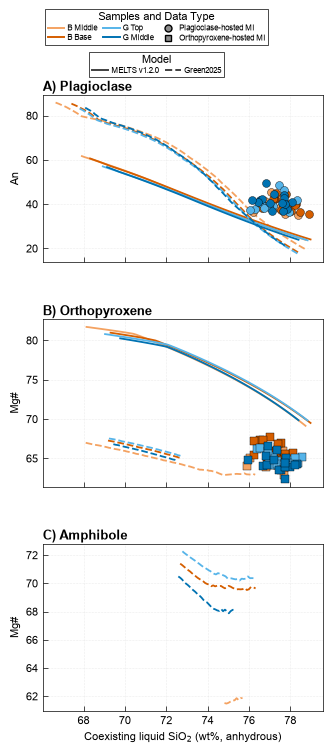

In [6]:
figure, axes = plt.subplots(3, 1, figsize=(SINGLE_COLUMN_WIDTH_IN, MAXIMUM_RECOMMENDED_HEIGHT_IN), sharex=True)
axes = np.asarray(axes)
figure.subplots_adjust(left=0.18, right=0.97, bottom=0.08, top=0.87, hspace=0.34)

for sample_key in SAMPLE_ORDER:
    color = SAMPLE_COLORS[sample_key]
    melts_plag = crystal_chemistry_melts[sample_key].dropna(subset=['An_Plag'])
    melts_opx = crystal_chemistry_melts[sample_key].dropna(subset=['Mg_number_Opx'])
    green_plag = crystal_chemistry_green[sample_key].dropna(subset=['An_Plag'])
    green_opx = crystal_chemistry_green[sample_key].dropna(subset=['Mg_number_Opx'])
    green_amp = crystal_chemistry_green[sample_key].dropna(subset=['Mg_number_Amp'])

    axes[0].plot(melts_plag['SiO2_Liq_anhydrous'], melts_plag['An_Plag'], color=color, linestyle='-', linewidth=1.3)
    axes[0].plot(green_plag['SiO2_Liq_anhydrous'], green_plag['An_Plag'], color=color, linestyle='--', linewidth=1.3)
    axes[1].plot(melts_opx['SiO2_Liq_anhydrous'], melts_opx['Mg_number_Opx'], color=color, linestyle='-', linewidth=1.3)
    axes[1].plot(green_opx['SiO2_Liq_anhydrous'], green_opx['Mg_number_Opx'], color=color, linestyle='--', linewidth=1.3)
    axes[2].plot(green_amp['SiO2_Liq_anhydrous'], green_amp['Mg_number_Amp'], color=color, linestyle='--', linewidth=1.3)

    plag_data = plag_points.loc[plag_points['geologic_sample'].eq(sample_key)]
    opx_data = opx_points.loc[opx_points['geologic_sample'].eq(sample_key)]
    axes[0].scatter(plag_data['SiO2'], plag_data['An#_host'], color=color, marker='o', s=(6.0 - MINIMUM_LINE_WIDTH_PT)**2, edgecolor='black', linewidth=MINIMUM_LINE_WIDTH_PT, zorder=3)
    axes[1].scatter(opx_data['SiO2'], opx_data['Mg#_host'], color=color, marker='s', s=(6.0 - MINIMUM_LINE_WIDTH_PT)**2, edgecolor='black', linewidth=MINIMUM_LINE_WIDTH_PT, zorder=3)

axes[0].set_ylabel('An')
axes[1].set_ylabel('Mg#')
axes[2].set_ylabel('Mg#')
axes[2].set_xlabel('Coexisting liquid SiO$_2$ (wt%, anhydrous)')
for axis, panel_label, title in zip(axes, ['A)','B)','C)'], ['Plagioclase','Orthopyroxene','Amphibole']):
    axis.set_title(f'{panel_label} {title}', loc='left', fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', pad=3)
    axis.grid(True, linestyle=':', linewidth=0.4, color='0.79', alpha=0.65)
    axis.set_axisbelow(True)
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)

sample_handles = [Line2D([], [], color=SAMPLE_COLORS[key], linewidth=1.4, label=SAMPLE_LABELS[key]) for key in SAMPLE_ORDER]
model_handles = [Line2D([], [], color='0.25', linestyle='-', linewidth=1.4, label='MELTS v1.2.0'), Line2D([], [], color='0.25', linestyle='--', linewidth=1.4, label='Green2025')]
host_handles = [Line2D([], [], marker='o', linestyle='none', markerfacecolor='0.55', markeredgecolor='black', markersize=5, label='Plagioclase-hosted MI'), Line2D([], [], marker='s', linestyle='none', markerfacecolor='0.55', markeredgecolor='black', markersize=5, label='Orthopyroxene-hosted MI')]
samples_legend = figure.legend(handles=sample_handles + host_handles, title='Samples and Data Type', loc='upper center', bbox_to_anchor=(0.5, 0.985), ncol=3, frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0, fontsize=6.0, title_fontsize=BASE_TEXT_SIZE_PT, handletextpad=0.35, labelspacing=0.2, columnspacing=0.7, borderpad=0.3)
samples_legend.get_frame().set_linewidth(0.5)
model_legend = figure.legend(handles=model_handles, title='Model', loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=2, frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0, fontsize=6.0, title_fontsize=BASE_TEXT_SIZE_PT, handletextpad=0.35, labelspacing=0.2, columnspacing=0.7, borderpad=0.3)
model_legend.get_frame().set_linewidth(0.5)

output_stem = OUTPUT_DIRECTORY / 'Figure_S23_Mineral_Compositions'
figure.savefig(output_stem.with_suffix('.pdf'), format='pdf', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(output_stem.with_suffix('.png'), format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(output_stem.with_suffix('.svg'), format='svg', dpi=EXPORT_DPI, facecolor='white', transparent=False)
plt.show()

## 7. Short output check

In [7]:
if len(MI) == 0 or len(MI_parameters) != 4:
    raise ValueError('The established Figure S23 melt-inclusion population or parameters changed.')
if len(axes) != 3:
    raise ValueError('Figure S23 must contain three panels.')
if any('An#' in axis.get_ylabel() for axis in axes):
    raise ValueError('The plotted plagioclase axis still contains An#.')
if hashlib.sha256(S1_PATH.read_bytes()).hexdigest() != SOURCE_HASH_BEFORE:
    raise RuntimeError('The S1 source workbook changed during execution.')
for suffix in ['.png','.pdf','.svg']:
    if not (OUTPUT_DIRECTORY / f'Figure_S23_Mineral_Compositions{suffix}').is_file():
        raise FileNotFoundError(f'Missing Figure S23 export: {suffix}')
with Image.open(OUTPUT_DIRECTORY / 'Figure_S23_Mineral_Compositions.png') as image:
    print(f'Final PNG dimensions: {image.size}')
print('Figure S23 check passed: MELTS/Green2025 runs retained, An# display label changed to An, and exports were created.')

Final PNG dimensions: (1065, 2340)
Figure S23 check passed: MELTS/Green2025 runs retained, An# display label changed to An, and exports were created.
